# The Most Efficient NBA Duo: Data Analysis
**MIS 433 Course Project | Sam Nocera & Jackson Hardy | Fall 2026**

## Background and motivation
Basketball is played in combinations. A coach does not just pick the five best players, he picks the pairs that work best together. A two-man lineup stat tells us how the team performs **while both players are on the floor at the same time**.

**Business question:** Which two-player duo on each NBA team is the most efficient, and how do the best duos compare across the league?

**Who benefits:** coaches (rotations and closing lineups), front offices (trades and contracts: keep the pairs that work), and analysts, fantasy players, and fans.

## Plan
1. Load and clean the 2-man lineup data from NBA.com Advanced Stats (2025-26 full season and 2026-27 season so far)
2. Explore the data
3. Use a regression model to see which stats drive a duo's Net Rating
4. Build a **Duo Efficiency Score (DES)** and run it under four different weighting models
5. Find the best duo on every team, rank them league-wide, and compare the models
6. Check whether last season's score predicts this season's results
7. Save the scored data for the application notebook


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Load the data

**Source:** [NBA.com Advanced Stats](https://www.nba.com/stats/lineups/advanced) → Lineups → Advanced → 2-man lineups, exported to CSV.

| File | Season | Rows | Notes |
|---|---|---|---|
| `duos_train_2025_26.csv` | 2025-26 (full season) | 2,000 | top 2,000 duos by minutes |
| `duos_test_2026_27.csv` | 2026-27 (through Nov 24, 2026) | 2,000 | season is about 16 games old |

We use the full 2025-26 season to build the scores (the "train" season), then check them against the 2026-27 season (the "test" season).

In [2]:
# Data files are stored in our GitHub repo
data_url = 'https://raw.githubusercontent.com/samnocera05-ui/mis433/main/final-project/data/'

duos = pd.read_csv(data_url + 'duos_train_2025_26.csv')
duos_new = pd.read_csv(data_url + 'duos_test_2026_27.csv')

print(duos.shape)
print(duos_new.shape)

(2000, 26)
(2017, 18)


In [3]:
duos.head()

,Lineups,TEAM,GP,MIN,OffRtg,DefRtg,NetRtg,AST%,AST/TO,AST Ratio,...,PACE,PIE,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,K. Durant - A. Thompson,HOU,76,2157,117.0,111.6,5.4,60.6,1.74,18.3,...,99.23,54.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,J. Smith Jr. - A. Thompson,HOU,75,2130,117.4,111.5,5.9,60.2,1.78,18.2,...,98.11,53.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,K. Durant - J. Smith Jr.,HOU,74,2034,117.7,112.3,5.4,60.5,1.76,18.4,...,98.47,53.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,A. Sengun - A. Thompson,HOU,70,1978,117.6,112.3,5.3,60.8,1.81,18.6,...,98.81,53.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,N. Alexander-Walker - J. Johnson,ATL,71,1978,115.8,111.0,4.8,69.7,2.30,20.9,...,104.63,52.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Key variables
| Column | Meaning |
|---|---|
| `Lineups` | the two players, e.g. "N. Jokić - J. Murray" |
| `TEAM` | team abbreviation |
| `GP`, `MIN` | games and minutes the two played together |
| `OffRtg` | points the team **scores** per 100 possessions with both on the floor (higher is better) |
| `DefRtg` | points the team **allows** per 100 possessions (lower is better) |
| `NetRtg` | OffRtg minus DefRtg: the overall margin |
| `TS%`, `eFG%` | shooting efficiency |
| `AST%`, `AST/TO`, `AST Ratio` | ball movement and ball security |
| `OREB%`, `DREB%`, `REB%` | share of available rebounds grabbed |
| `PACE` | possessions per 48 minutes |
| `PIE` | Player Impact Estimate: share of all game events the lineup wins |

## 2. Clean the data

In [4]:
# Problem 1: the 2025-26 export has 8 empty columns named 'Unnamed: 18' ... 'Unnamed: 25'
duos.isna().sum()

Lineups           0
TEAM              0
GP                0
MIN               0
OffRtg            0
DefRtg            0
NetRtg            0
AST%              0
AST/TO            0
AST Ratio         0
OREB%             0
DREB%             0
REB%              0
TO Ratio          0
eFG%              0
TS%               0
PACE              0
PIE               0
Unnamed: 18    2000
Unnamed: 19    2000
Unnamed: 20    2000
Unnamed: 21    2000
Unnamed: 22    2000
Unnamed: 23    2000
Unnamed: 24    2000
Unnamed: 25    2000
dtype: int64

In [5]:
# Drop every column whose name contains 'Unnamed'
duos = duos.drop(columns=duos.columns[duos.columns.str.contains('Unnamed')])
duos.shape

(2000, 18)

In [6]:
# Problem 2: the 2026-27 export picked up 17 rows of website footer text (no team, no stats)
duos_new.tail(17)

,Lineups,TEAM,GP,MIN,OffRtg,DefRtg,NetRtg,AST%,AST/TO,AST Ratio,OREB%,DREB%,REB%,TO Ratio,eFG%,TS%,PACE,PIE
2000,League Pass,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2001,Customer Support,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2003,"© 2026 NBA Media Ventures, LLC. All rights res...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2004,Privacy Policy,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005,EEA/UK Privacy Statement,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006,UK Tax Strategy Statement,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007,Brazil Privacy Statement,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008,Colorado Consumer Privacy Statement,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2009,California Consumer Privacy Statement,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# Drop rows with no team
duos_new = duos_new.dropna(subset=['TEAM'])
duos_new.shape

(2000, 18)

In [8]:
# Problem 3: 'TO Ratio' was exported rounded to one decimal, so almost every value is 0.1 or 0.2.
# It carries no information, so we drop it from both seasons.
print(duos['TO Ratio'].value_counts())

duos = duos.drop(columns=['TO Ratio'])
duos_new = duos_new.drop(columns=['TO Ratio'])

TO Ratio
0.1    1392
0.2     608
Name: count, dtype: int64


In [9]:
# Problem 4: some duos look like duplicates. They are not: OKC has two players listed as 'J. Williams'
# (Jalen Williams and Jaylin Williams), so the same duo name appears twice with different stats.
duos[duos['Lineups'] == 'S. Gilgeous-Alexander - J. Williams']

,Lineups,TEAM,GP,MIN,OffRtg,DefRtg,NetRtg,AST%,AST/TO,AST Ratio,OREB%,DREB%,REB%,eFG%,TS%,PACE,PIE
333,S. Gilgeous-Alexander - J. Williams,OKC,54,775,121.8,100.7,21.2,57.1,2.27,17.7,24.3,69.0,48.7,58.4,63.1,102.50,61.3
658,S. Gilgeous-Alexander - J. Williams,OKC,29,531,120.3,104.8,15.5,56.2,2.35,18.3,26.6,71.5,50.4,58.0,61.7,104.07,58.7


In [10]:
# We cannot tell the two J. Williams apart, so we remove OKC duos that include 'J. Williams' from both seasons.
print('2025-26 rows removed:', (duos['Lineups'].str.contains('J. Williams') & (duos['TEAM'] == 'OKC')).sum())
duos = duos[~(duos['Lineups'].str.contains('J. Williams') & (duos['TEAM'] == 'OKC'))]
duos_new = duos_new[~(duos_new['Lineups'].str.contains('J. Williams') & (duos_new['TEAM'] == 'OKC'))]
print(duos.shape, duos_new.shape)

2025-26 rows removed: 18
(1982, 17) (1984, 17)


In [11]:
# Split the duo name into two player columns
duos[['Player_1', 'Player_2']] = duos['Lineups'].str.split(' - ', expand=True)
duos_new[['Player_1', 'Player_2']] = duos_new['Lineups'].str.split(' - ', expand=True)
duos[['Lineups', 'Player_1', 'Player_2', 'TEAM']].head()

,Lineups,Player_1,Player_2,TEAM
0,K. Durant - A. Thompson,K. Durant,A. Thompson,HOU
1,J. Smith Jr. - A. Thompson,J. Smith Jr.,A. Thompson,HOU
2,K. Durant - J. Smith Jr.,K. Durant,J. Smith Jr.,HOU
3,A. Sengun - A. Thompson,A. Sengun,A. Thompson,HOU
4,N. Alexander-Walker - J. Johnson,N. Alexander-Walker,J. Johnson,ATL


## 3. Explore the data

### How many minutes do duos play together?
A duo that played 180 minutes can post a great Net Rating by luck. We need a minimum number of minutes.

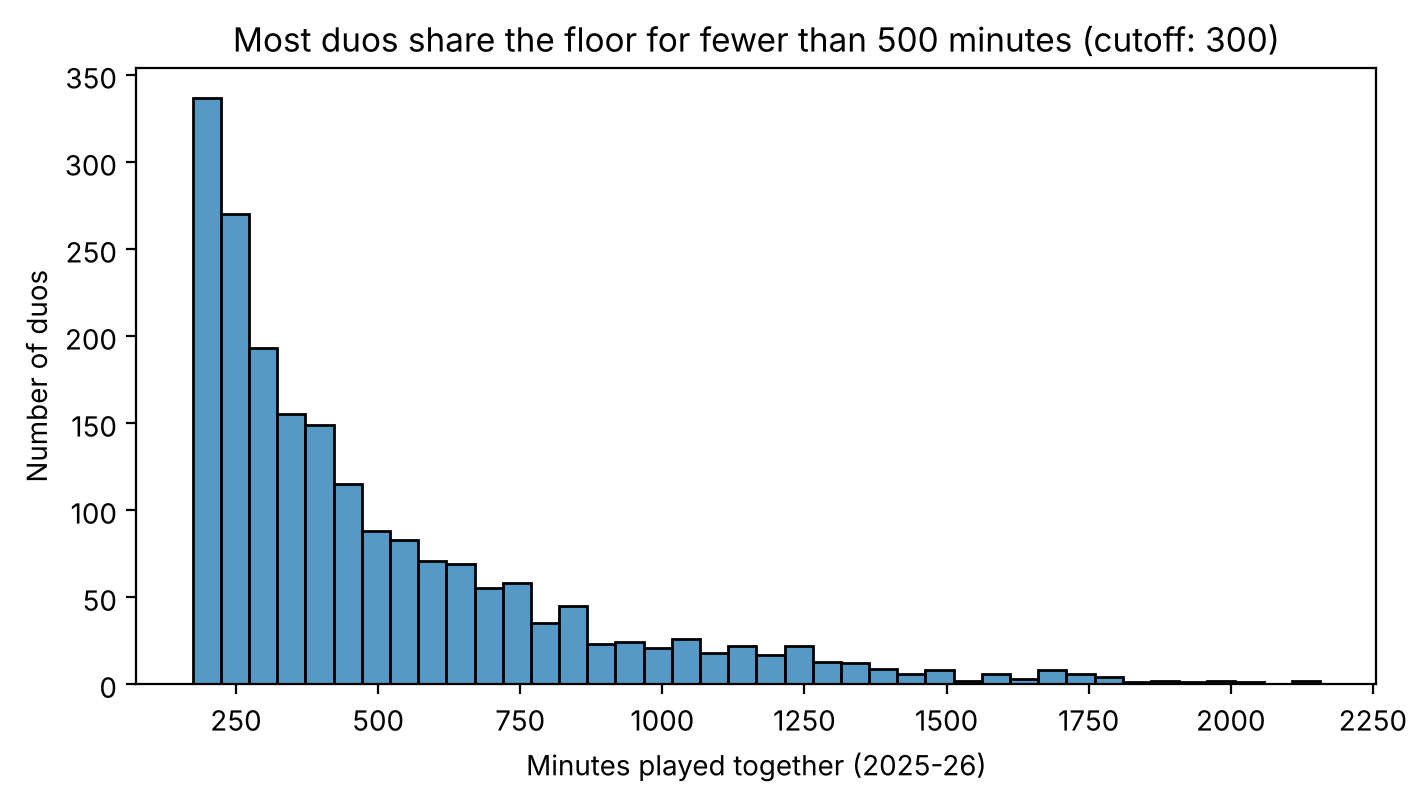

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=duos, x='MIN', bins=40, ax=ax)
ax.set_xlabel('Minutes played together (2025-26)')
ax.set_ylabel('Number of duos')
ax.set_title('Most duos share the floor for fewer than 500 minutes (cutoff: 300)')
plt.show()

In [13]:
# Keep duos with at least 300 minutes together (about 4 full games' worth)
MIN_MINUTES = 300
duos = duos[duos['MIN'] >= MIN_MINUTES]

print('Duos kept:', duos.shape[0])
print('Duos per team:')
duos['TEAM'].value_counts().describe()

Duos kept: 1259
Duos per team:


count    30.000000
mean     41.966667
std       4.867084
min      34.000000
25%      38.000000
50%      43.000000
75%      46.000000
max      49.000000
Name: count, dtype: float64

In [14]:
duos.describe()

,GP,MIN,OffRtg,DefRtg,NetRtg,AST%,AST/TO,AST Ratio,OREB%,DREB%,REB%,eFG%,TS%,PACE,PIE
count,1259.000000,1259.000000,1259.000000,1259.000000,1259.000000,1259.000000,1259.000000,1259.000000,1259.000000,1259.000000,1259.000000,1259.000000,1259.000000,1259.000000,1259.00000
mean,46.949166,656.015091,112.811994,112.160683,0.648928,63.697538,1.896847,18.526608,30.525496,69.587927,50.111914,54.699762,58.298253,102.476338,50.32923
std,14.193326,342.319994,5.372206,5.413403,8.348317,5.021077,0.300454,1.453907,4.194685,2.895157,2.593596,2.494629,2.368473,2.592891,4.39832
min,13.000000,300.000000,94.000000,92.700000,-22.600000,48.100000,1.110000,14.200000,17.300000,59.700000,43.300000,46.700000,50.600000,95.220000,36.80000
25%,36.000000,397.500000,109.300000,108.700000,-5.300000,60.200000,1.680000,17.500000,27.450000,67.700000,48.300000,53.100000,56.700000,100.660000,47.30000
50%,46.000000,547.000000,113.000000,112.000000,1.300000,63.500000,1.880000,18.400000,30.100000,69.800000,49.900000,54.700000,58.200000,102.410000,50.60000
75%,57.000000,807.000000,116.300000,115.750000,6.400000,67.200000,2.090000,19.600000,33.200000,71.600000,51.800000,56.300000,59.800000,104.295000,53.30000
max,82.000000,2157.000000,130.200000,129.800000,27.100000,77.100000,3.220000,23.100000,47.400000,79.700000,59.900000,65.700000,68.000000,109.330000,65.60000


### Net Rating by team
Good teams have many positive duos. The spread inside each team shows that **which pair** is on the floor matters.

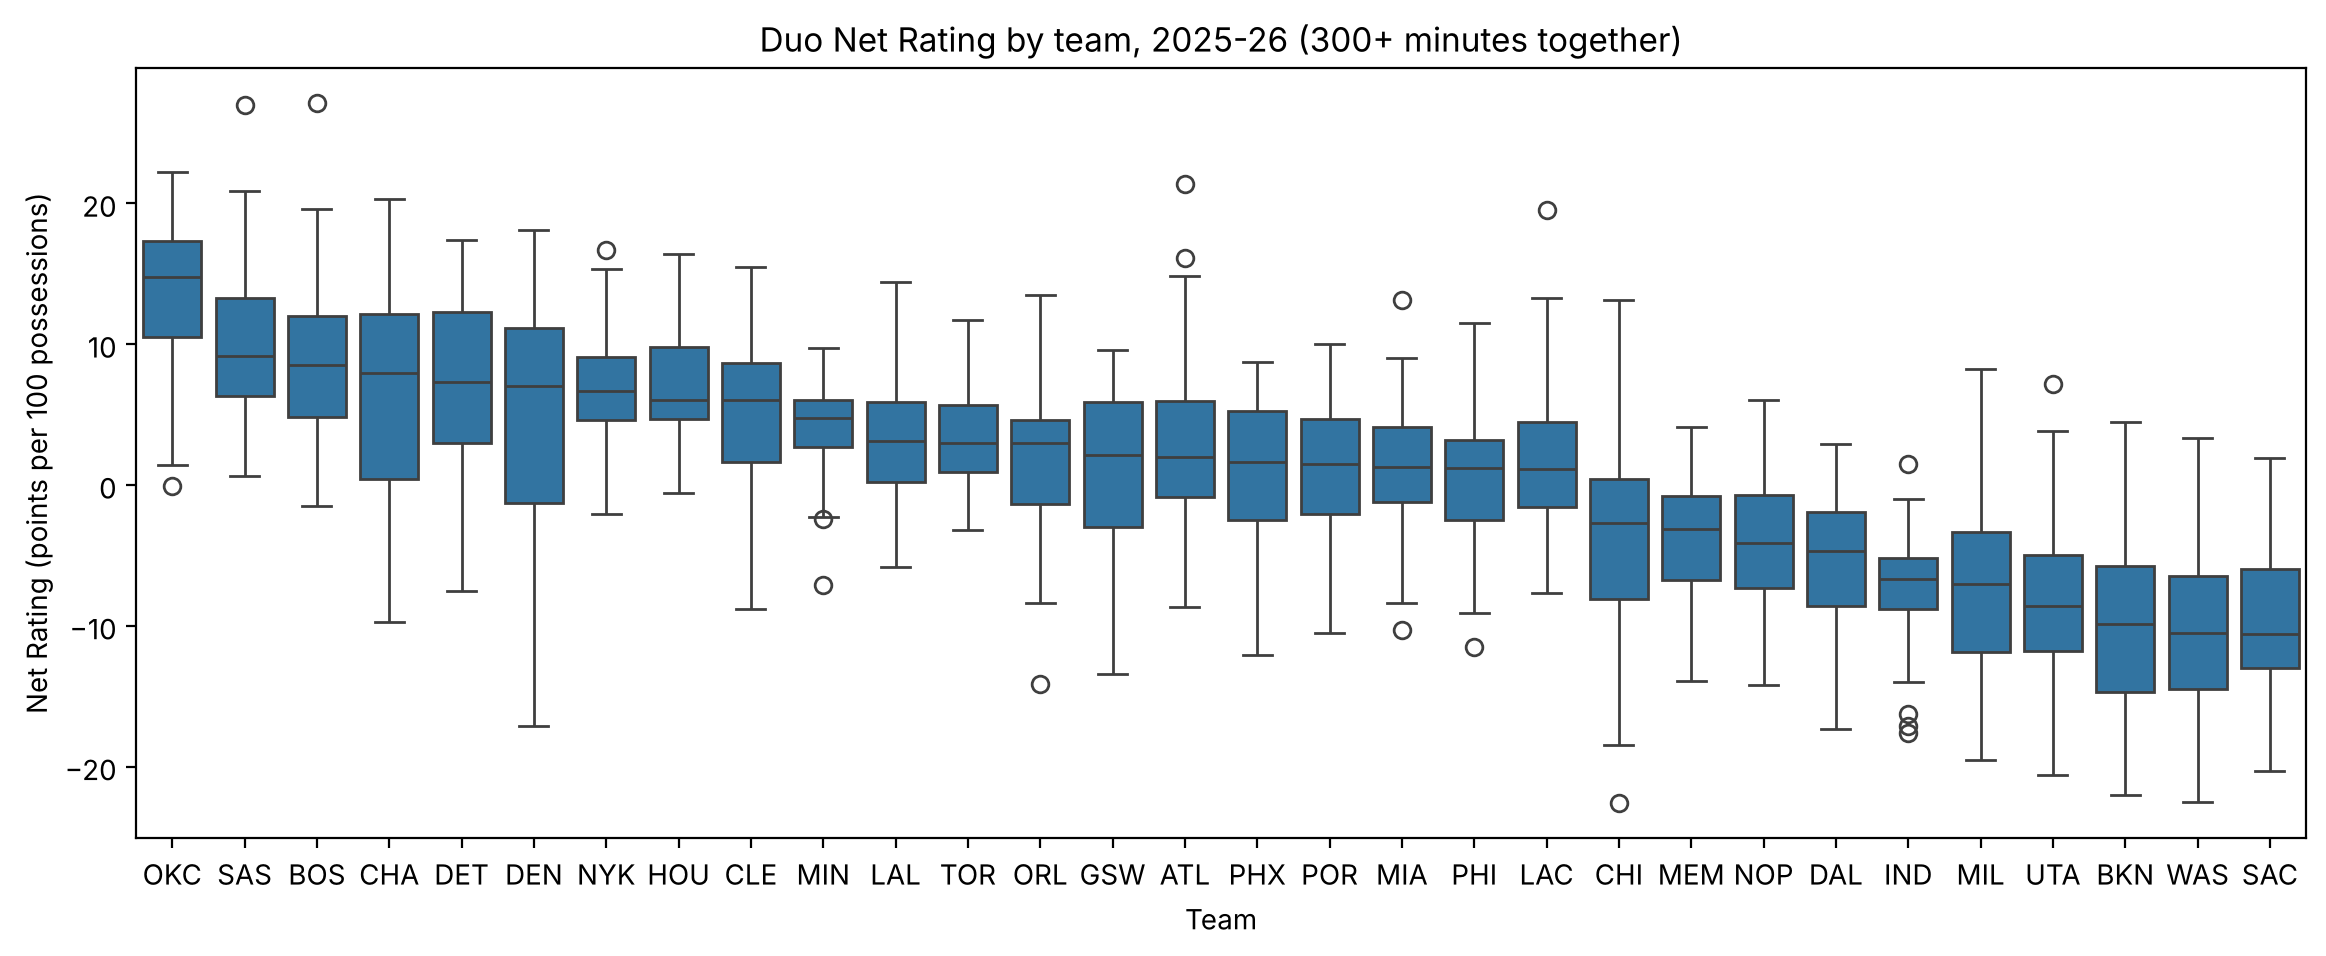

In [15]:
# Order teams by their median duo Net Rating
team_order = duos.groupby('TEAM')['NetRtg'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=duos, x='TEAM', y='NetRtg', order=team_order, ax=ax)
ax.set_xlabel('Team')
ax.set_ylabel('Net Rating (points per 100 possessions)')
ax.set_title('Duo Net Rating by team, 2025-26 (300+ minutes together)')
plt.show()

### Offense vs defense
Each dot is a duo. Bottom-right on this chart = scores a lot **and** allows little (lower DefRtg is better).

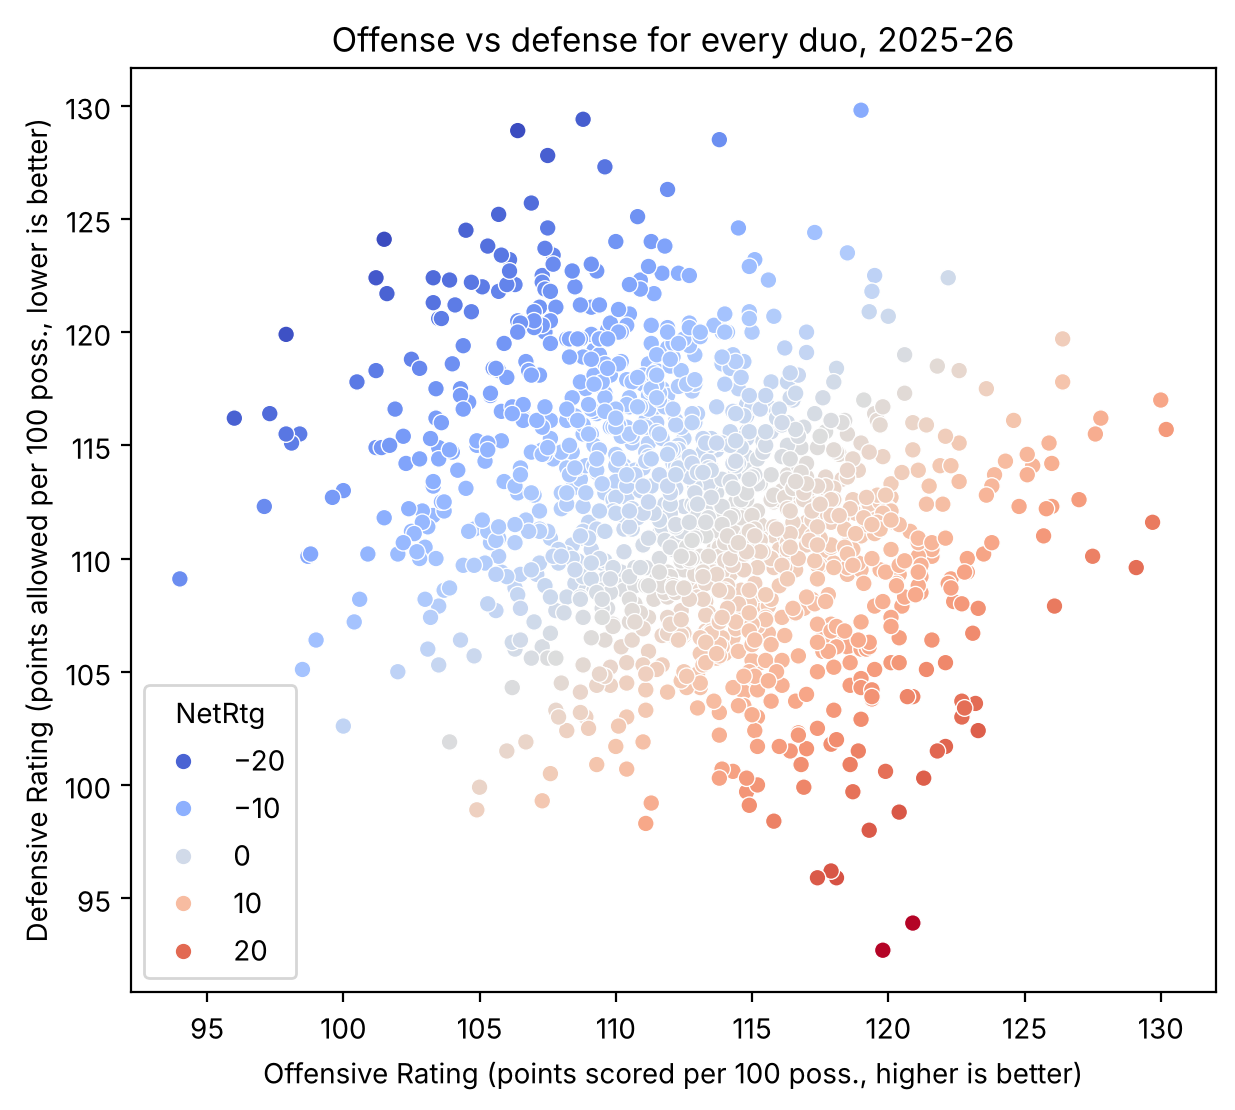

In [16]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=duos, x='OffRtg', y='DefRtg', hue='NetRtg', palette='coolwarm', ax=ax)
ax.set_xlabel('Offensive Rating (points scored per 100 poss., higher is better)')
ax.set_ylabel('Defensive Rating (points allowed per 100 poss., lower is better)')
ax.set_title('Offense vs defense for every duo, 2025-26')
plt.show()

## 4. Which stats drive a duo's Net Rating?

We fit a **linear regression**: Net Rating explained by shooting, ball security, rebounding, passing, and pace.
We scale each input to 0-1 with `MinMaxScaler` first so the coefficients can be compared with each other.

In [17]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

features = ['TS%', 'AST/TO', 'REB%', 'AST%', 'PACE']
X = duos[features]
y = duos['NetRtg']

min_max_scaler = MinMaxScaler()
X_scaled = min_max_scaler.fit_transform(X)

lm = LinearRegression()
lm.fit(X_scaled, y)

print('R^2:', lm.score(X_scaled, y))
print('RMSE:', root_mean_squared_error(y, lm.predict(X_scaled)))

R^2: 0.67929935631266
RMSE: 4.725810364560545


In [18]:
# Coefficients: how many points of Net Rating going from the lowest to the highest value of each stat is worth
coefs = pd.DataFrame({'Stat': features, 'Coefficient': lm.coef_}).sort_values('Coefficient', ascending=False)
coefs

,Stat,Coefficient
2,REB%,27.056026
0,TS%,21.378577
1,AST/TO,19.654108
4,PACE,-0.574924
3,AST%,-9.429058


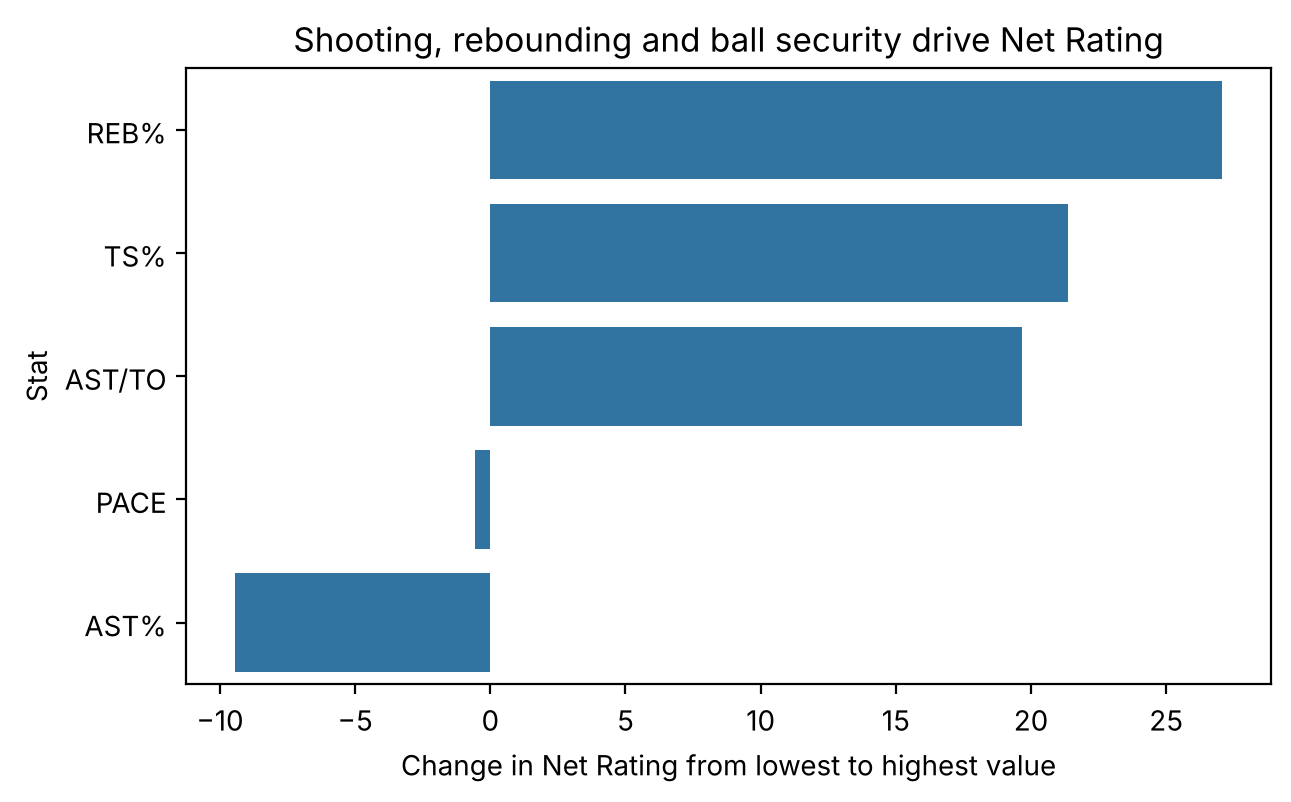

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=coefs, x='Coefficient', y='Stat', ax=ax)
ax.set_xlabel('Change in Net Rating from lowest to highest value')
ax.set_title('Shooting, rebounding and ball security drive Net Rating')
plt.show()

**Takeaway:** shooting efficiency (TS%), rebounding (REB%), and ball security (AST/TO) carry most of the weight, while pace barely matters. This tells us which stats belong in the efficiency score.

## 5. Duo Efficiency Score (DES)

Steps:
1. Pick seven stats: `NetRtg`, `OffRtg`, `DefRtg`, `TS%`, `AST/TO`, `REB%`, `PIE`
2. Scale each one to 0-1 with `MinMaxScaler` (0 = worst duo in the league, 1 = best)
3. Flip `DefRtg` (1 - value), because a lower defensive rating is better
4. Multiply each stat by a weight and add them up, then multiply by 100 → a score from 0 to 100

Different weights = different models. We build four:

| Stat | Balanced | Offense | Defense | Impact |
|---|---|---|---|---|
| NetRtg | 0.30 | 0.10 | 0.10 | 0.40 |
| OffRtg | 0.15 | 0.35 | 0.05 | 0 |
| DefRtg (flipped) | 0.15 | 0.05 | 0.45 | 0 |
| TS% | 0.15 | 0.30 | 0.05 | 0 |
| AST/TO | 0.10 | 0.15 | 0.05 | 0 |
| REB% | 0.10 | 0.05 | 0.30 | 0 |
| PIE | 0.05 | 0 | 0 | 0.60 |


In [20]:
score_stats = ['NetRtg', 'OffRtg', 'DefRtg', 'TS%', 'AST/TO', 'REB%', 'PIE']

scaler = MinMaxScaler()
scaled = pd.DataFrame(scaler.fit_transform(duos[score_stats]), columns=score_stats, index=duos.index)

# Lower DefRtg is better, so flip it
scaled['DefRtg'] = 1 - scaled['DefRtg']
scaled.head()

,NetRtg,OffRtg,DefRtg,TS%,AST/TO,REB%,PIE
0,0.563380,0.635359,0.490566,0.454023,0.298578,0.716867,0.597222
1,0.573441,0.646409,0.493261,0.436782,0.317536,0.680723,0.576389
2,0.563380,0.654696,0.471698,0.448276,0.308057,0.680723,0.583333
3,0.561368,0.651934,0.471698,0.465517,0.331754,0.656627,0.586806
4,0.551308,0.602210,0.506739,0.511494,0.563981,0.337349,0.538194


In [21]:
models = {
    'Balanced': {'NetRtg': 0.30, 'OffRtg': 0.15, 'DefRtg': 0.15, 'TS%': 0.15, 'AST/TO': 0.10, 'REB%': 0.10, 'PIE': 0.05},
    'Offense':  {'NetRtg': 0.10, 'OffRtg': 0.35, 'DefRtg': 0.05, 'TS%': 0.30, 'AST/TO': 0.15, 'REB%': 0.05, 'PIE': 0.00},
    'Defense':  {'NetRtg': 0.10, 'OffRtg': 0.05, 'DefRtg': 0.45, 'TS%': 0.05, 'AST/TO': 0.05, 'REB%': 0.30, 'PIE': 0.00},
    'Impact':   {'NetRtg': 0.40, 'OffRtg': 0.00, 'DefRtg': 0.00, 'TS%': 0.00, 'AST/TO': 0.00, 'REB%': 0.00, 'PIE': 0.60},
}

def duo_score(scaled, weights):
    # weighted sum of the scaled stats, on a 0-100 scale
    total = 0
    for stat, weight in weights.items():
        total = total + scaled[stat] * weight
    return total * 100

for name, weights in models.items():
    duos['DES_' + name] = duo_score(scaled, weights)

duos[['Lineups', 'TEAM', 'MIN', 'NetRtg', 'DES_Balanced', 'DES_Offense', 'DES_Defense', 'DES_Impact']].sort_values('DES_Balanced', ascending=False).head(10)

,Lineups,TEAM,MIN,NetRtg,DES_Balanced,DES_Offense,DES_Defense,DES_Impact
617,V. Wembanyama - D. Harper,SAS,560,27.0,84.528737,73.981950,87.344768,99.919517
676,D. White - H. González,BOS,522,27.1,80.921484,67.924617,83.964109,98.333333
477,A. Gordon - N. Jokić,DEN,650,18.1,80.061581,88.195515,65.601307,80.673206
194,D. Vassell - V. Wembanyama,SAS,1003,20.9,77.169580,74.727961,72.278232,87.301727
102,J. Champagnie - V. Wembanyama,SAS,1231,20.4,75.820587,72.477488,72.188712,84.607646
414,I. Hartenstein - C. Holmgren,OKC,704,20.9,75.078062,68.909226,73.678781,87.510060
915,A. Caruso - C. Holmgren,OKC,411,21.7,74.645768,65.128061,75.946530,92.112257
812,A. Caruso - A. Mitchell,OKC,451,22.2,74.597446,66.965517,71.362866,90.639671
535,A. Caruso - S. Gilgeous-Alexander,OKC,612,21.6,73.963596,69.211840,66.402035,88.281774
1147,K. Leonard - D. Garland,LAC,336,19.5,73.026316,80.086752,53.385496,79.716633


## 6. The best duo on every team

In [22]:
# Rank duos inside each team (1 = best) under the Balanced model
duos['Team_Rank'] = duos.groupby('TEAM')['DES_Balanced'].rank(method='min', ascending=False)

best_duos = duos[duos['Team_Rank'] == 1].sort_values('DES_Balanced', ascending=False)
best_duos['League_Rank'] = best_duos['DES_Balanced'].rank(method='min', ascending=False)

best_duos[['League_Rank', 'TEAM', 'Lineups', 'MIN', 'OffRtg', 'DefRtg', 'NetRtg', 'DES_Balanced']]

,League_Rank,TEAM,Lineups,MIN,OffRtg,DefRtg,NetRtg,DES_Balanced
617,1.0,SAS,V. Wembanyama - D. Harper,560,120.9,93.9,27.0,84.528737
676,2.0,BOS,D. White - H. González,522,119.8,92.7,27.1,80.921484
477,3.0,DEN,A. Gordon - N. Jokić,650,129.7,111.6,18.1,80.061581
414,4.0,OKC,I. Hartenstein - C. Holmgren,704,121.3,100.3,20.9,75.078062
1147,5.0,LAC,K. Leonard - D. Garland,336,129.1,109.6,19.5,73.026316
417,6.0,ATL,C. McCollum - D. Daniels,700,119.3,98.0,21.4,72.613665
1151,7.0,CHA,G. Williams - S. James,335,118.7,99.7,19.0,72.214553
703,8.0,DET,A. Thompson - D. Jenkins,508,118.9,101.5,17.4,70.612075
317,9.0,CLE,D. Mitchell - D. Wade,801,123.3,107.8,15.5,69.407224
631,10.0,NYK,O. Anunoby - M. Robinson,548,122.1,105.4,16.7,68.889994


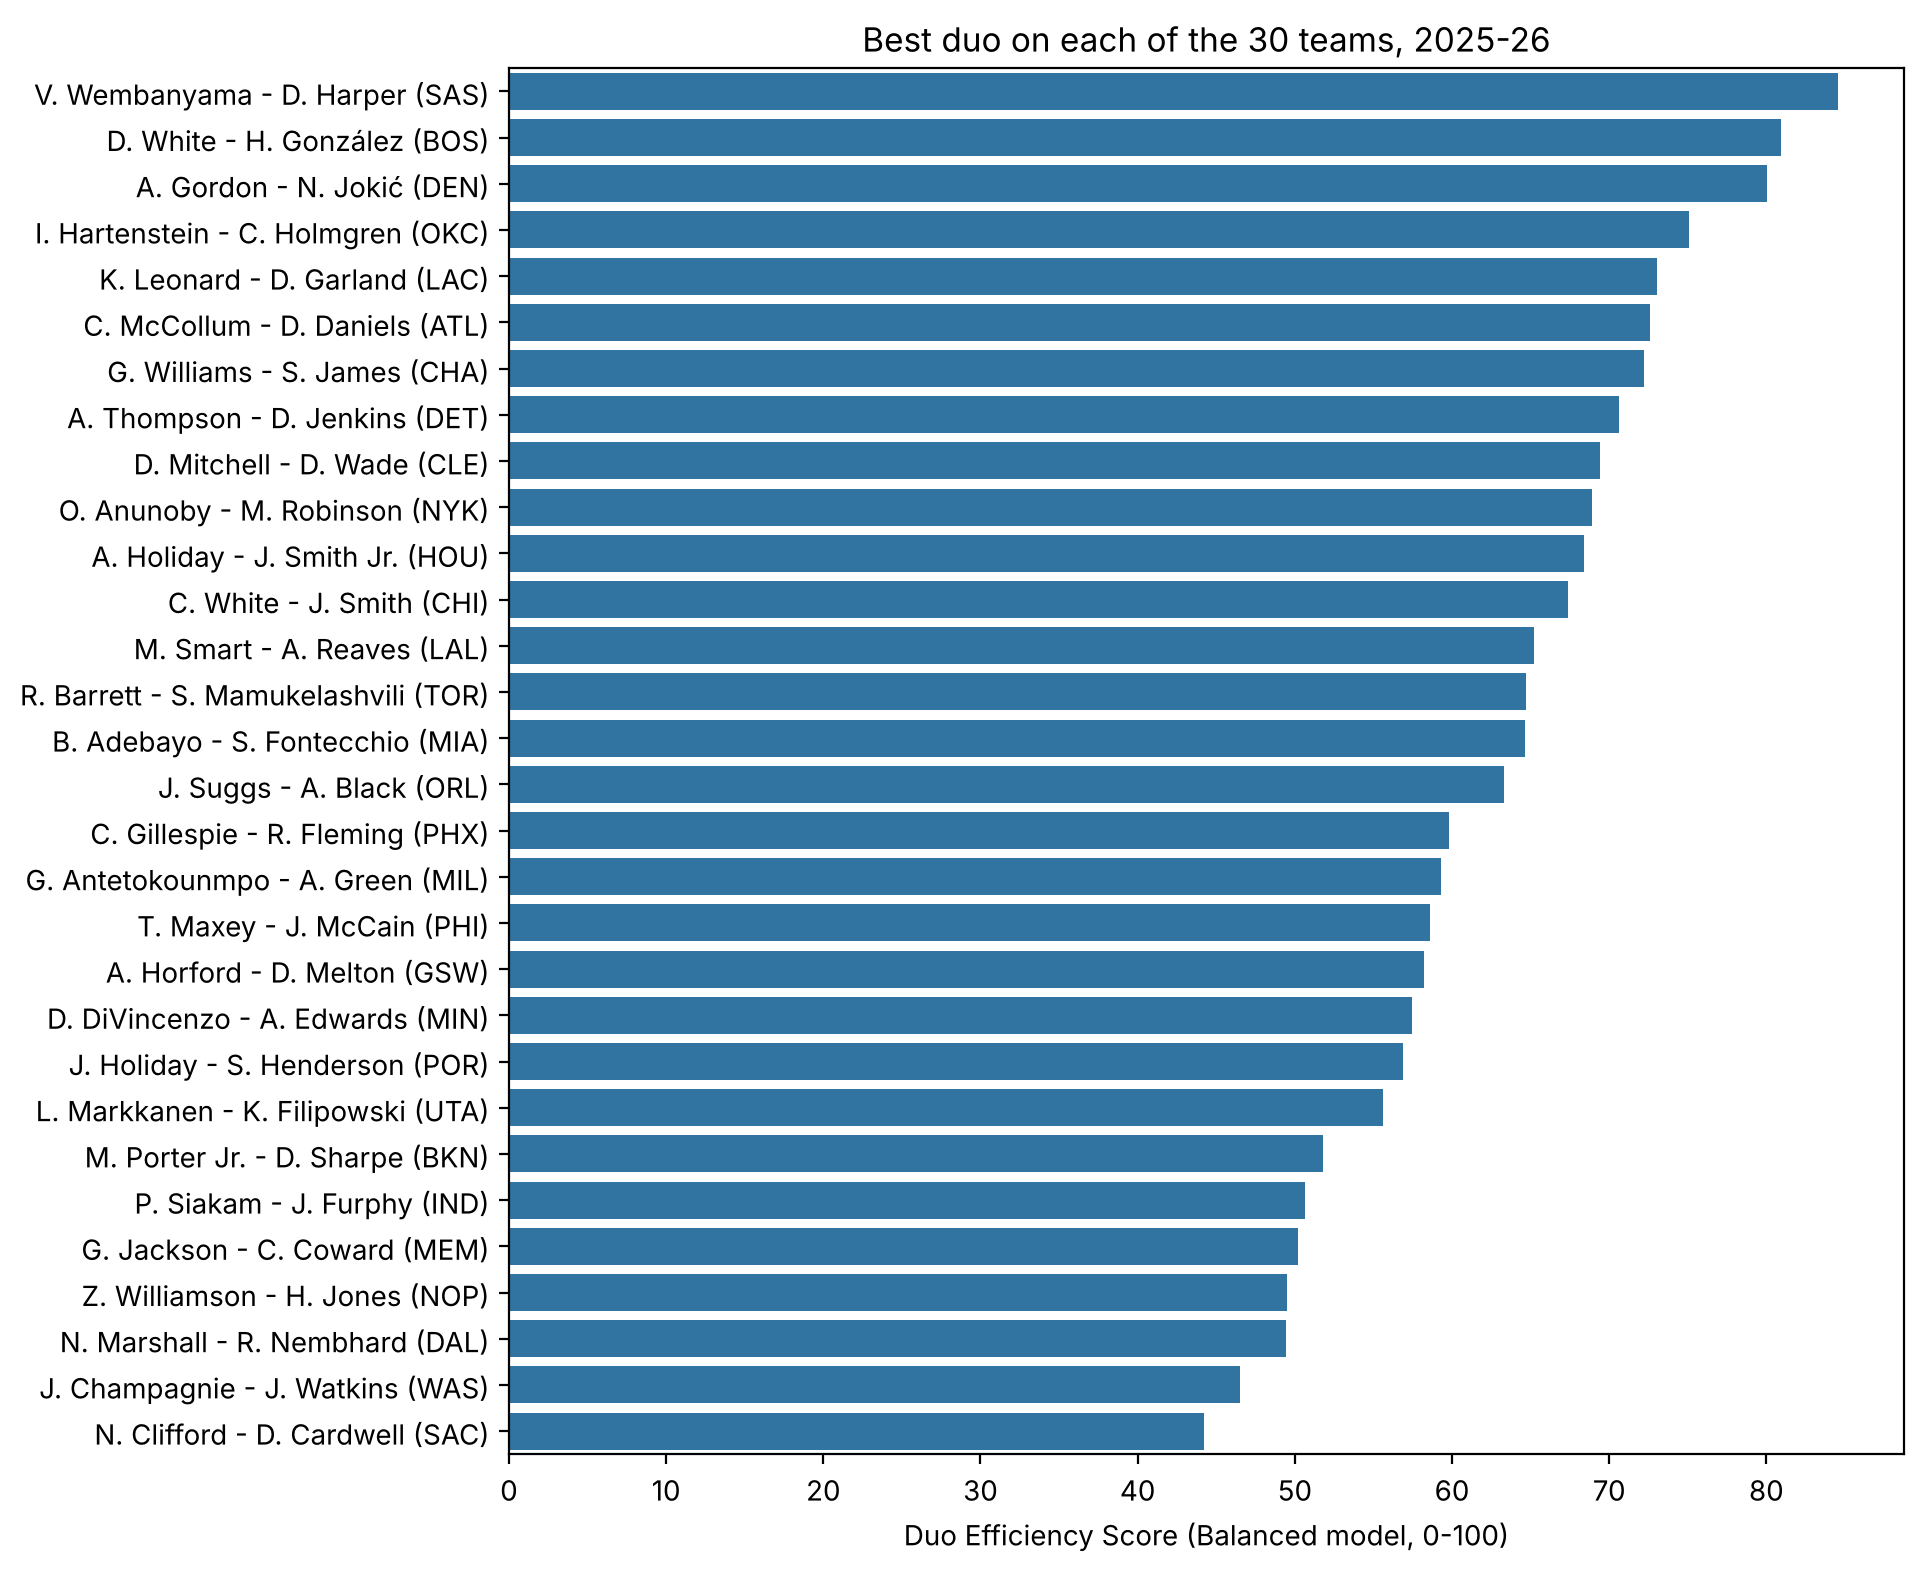

In [23]:
# Label each bar with the duo and the team
best_duos['Label'] = best_duos['Lineups'] + ' (' + best_duos['TEAM'] + ')'

fig, ax = plt.subplots(figsize=(9, 9))
sns.barplot(data=best_duos, x='DES_Balanced', y='Label', ax=ax)
ax.set_xlabel('Duo Efficiency Score (Balanced model, 0-100)')
ax.set_ylabel('')
ax.set_title('Best duo on each of the 30 teams, 2025-26')
plt.show()

## 7. Do different models pick different duos?

We find the best duo on every team under each of the four models, then compare.

In [24]:
best_by_model = best_duos[['TEAM', 'Lineups']].rename(columns={'Lineups': 'Balanced'})
for name in ['Offense', 'Defense', 'Impact']:
    rank = duos.groupby('TEAM')['DES_' + name].rank(method='min', ascending=False)
    top = duos[rank == 1][['TEAM', 'Lineups']].rename(columns={'Lineups': name})
    best_by_model = best_by_model.merge(top, on='TEAM')

# How many of the other 3 models agree with the Balanced pick?
best_by_model['Agree_with_Balanced'] = ((best_by_model['Offense'] == best_by_model['Balanced']).astype(int)
                                       + (best_by_model['Defense'] == best_by_model['Balanced']).astype(int)
                                       + (best_by_model['Impact'] == best_by_model['Balanced']).astype(int))
best_by_model = best_by_model.sort_values('Agree_with_Balanced')
best_by_model

,TEAM,Balanced,Offense,Defense,Impact,Agree_with_Balanced
3,OKC,I. Hartenstein - C. Holmgren,S. Gilgeous-Alexander - C. Holmgren,I. Hartenstein - I. Joe,A. Caruso - C. Holmgren,0
19,GSW,A. Horford - D. Melton,S. Curry - J. Butler III,M. Moody - B. Podziemski,J. Butler III - Q. Post,0
26,NOP,Z. Williamson - H. Jones,T. Murphy III - B. McGowens,Y. Missi - M. Peavy,T. Murphy III - K. Matković,0
6,CHA,G. Williams - S. James,L. Ball - M. Diabaté,G. Williams - S. James,J. Green - K. Knueppel,1
13,TOR,R. Barrett - S. Mamukelashvili,R. Barrett - S. Mamukelashvili,O. Agbaji - S. Mamukelashvili,G. Dick - J. Shead,1
21,POR,J. Holiday - S. Henderson,J. Holiday - S. Cissoko,J. Holiday - K. Murray,J. Holiday - S. Henderson,1
12,LAL,M. Smart - A. Reaves,L. Kennard - L. Dončić,J. Vanderbilt - R. Hachimura,M. Smart - A. Reaves,1
9,NYK,O. Anunoby - M. Robinson,J. Brunson - M. McBride,M. Robinson - M. McBride,O. Anunoby - M. Robinson,1
20,MIN,D. DiVincenzo - A. Edwards,D. DiVincenzo - A. Edwards,R. Gobert - J. Clark,D. DiVincenzo - B. Hyland,1
25,MEM,G. Jackson - C. Coward,G. Jackson - C. Coward,V. Williams Jr. - C. Coward,V. Williams Jr. - C. Coward,1


In [25]:
print('Teams where all 4 models pick the same best duo:', (best_by_model['Agree_with_Balanced'] == 3).sum(), 'of 30')
print('Teams where at least one model picks a different duo:', (best_by_model['Agree_with_Balanced'] < 3).sum(), 'of 30')

Teams where all 4 models pick the same best duo: 8 of 30
Teams where at least one model picks a different duo: 22 of 30


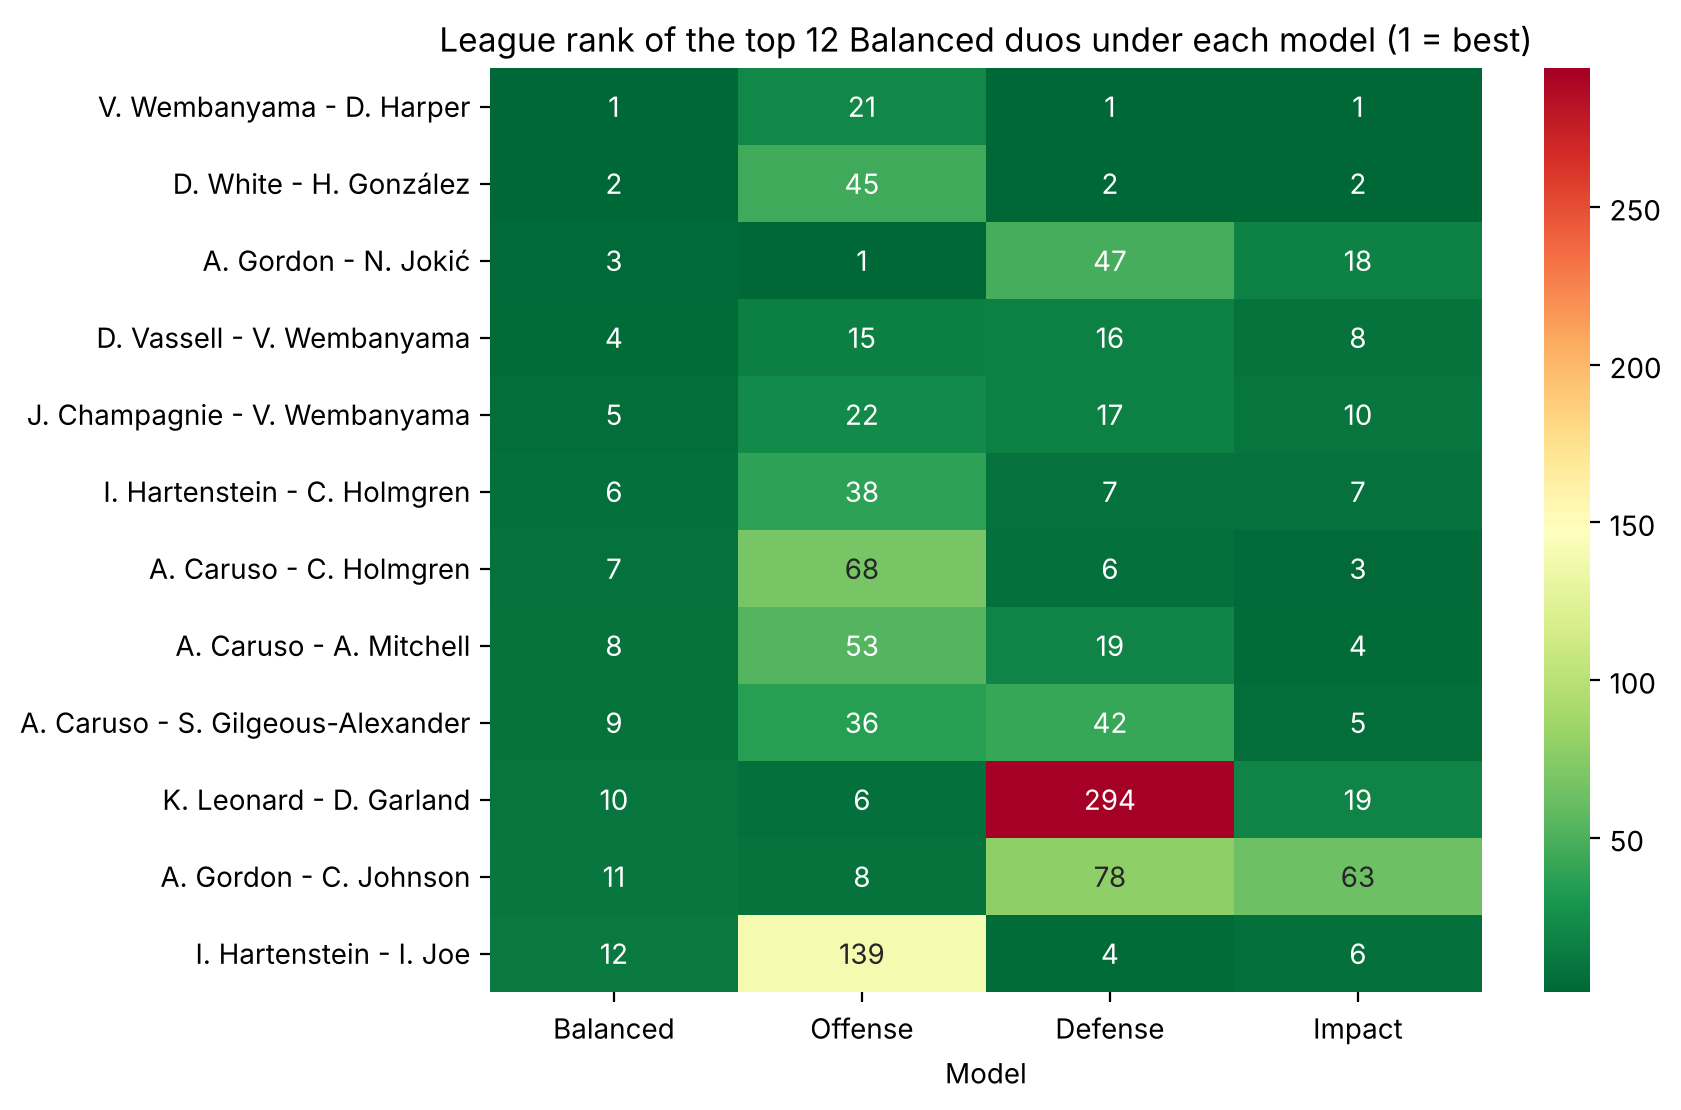

In [26]:
# How far does each duo's league-wide rank move between models?
for name in models:
    duos['Rank_' + name] = duos['DES_' + name].rank(method='min', ascending=False)

top12 = duos.sort_values('DES_Balanced', ascending=False).head(12)
rank_long = top12.melt(id_vars=['Lineups'], value_vars=['Rank_' + n for n in models], var_name='Model', value_name='League_Rank')
rank_long['Model'] = rank_long['Model'].str.replace('Rank_', '')

# Pivot back to a table: one row per duo, one column per model
rank_table = rank_long.pivot(index='Lineups', columns='Model', values='League_Rank')
rank_table = rank_table[['Balanced', 'Offense', 'Defense', 'Impact']].sort_values('Balanced')

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(data=rank_table, annot=True, fmt='.0f', cmap='RdYlGn_r', ax=ax)
ax.set_xlabel('Model')
ax.set_ylabel('')
ax.set_title('League rank of the top 12 Balanced duos under each model (1 = best)')
plt.show()

In [27]:
# Duos that are top 25 league-wide under every model: the most robust answers
robust = duos[(duos['Rank_Balanced'] <= 25) & (duos['Rank_Offense'] <= 25) & (duos['Rank_Defense'] <= 25) & (duos['Rank_Impact'] <= 25)]
robust[['Lineups', 'TEAM', 'MIN', 'NetRtg', 'Rank_Balanced', 'Rank_Offense', 'Rank_Defense', 'Rank_Impact']].sort_values('Rank_Balanced')

,Lineups,TEAM,MIN,NetRtg,Rank_Balanced,Rank_Offense,Rank_Defense,Rank_Impact
617,V. Wembanyama - D. Harper,SAS,560,27.0,1.0,21.0,1.0,1.0
194,D. Vassell - V. Wembanyama,SAS,1003,20.9,4.0,15.0,16.0,8.0
102,J. Champagnie - V. Wembanyama,SAS,1231,20.4,5.0,22.0,17.0,10.0


### Hub players: one player in many top duos
If the same player shows up in most of his team's top duos, the efficiency comes from **him**, not from a specific partnership.

In [28]:
# Take each team's top 3 duos (Balanced model) and count how often each player appears
top3 = duos[duos['Team_Rank'] <= 3]
players = top3.melt(id_vars=['TEAM'], value_vars=['Player_1', 'Player_2'], value_name='Player')
hubs = players.groupby(['TEAM', 'Player']).size().reset_index().rename(columns={0: 'Top3_Appearances'})
hubs = hubs.sort_values('Top3_Appearances', ascending=False)

print('Teams with a player in all 3 of their top duos:', (hubs['Top3_Appearances'] == 3).sum())
hubs[hubs['Top3_Appearances'] == 3]

Teams with a player in all 3 of their top duos: 10


,TEAM,Player,Top3_Appearances
0,ATL,C. McCollum,3
61,MEM,C. Coward,3
65,MIA,B. Adebayo,3
21,CHI,J. Smith,3
32,DEN,A. Gordon,3
106,POR,J. Holiday,3
113,SAC,N. Clifford,3
117,SAS,V. Wembanyama,3
70,MIL,G. Antetokounmpo,3
56,LAC,K. Leonard,3


## 8. Does the score hold up the next season?

We take duos that played together in **both** 2025-26 (300+ min) and 2026-27 (100+ min so far), and check whether last season's score predicts this season's Net Rating.

In [29]:
duos_new = duos_new[duos_new['MIN'] >= 100]

# Rename this season's columns so they do not clash with last season's
this_season = duos_new[['Lineups', 'TEAM', 'MIN', 'NetRtg']].rename(columns={'MIN': 'MIN_2026', 'NetRtg': 'NetRtg_2026'})
returning = duos.merge(this_season, on=['Lineups', 'TEAM'])
print('Returning duos:', returning.shape[0])

Returning duos: 327


In [30]:
# One simple regression per model: this season's Net Rating ~ last season's score
results = []
for name in models:
    X_r = returning[['DES_' + name]]
    y_r = returning['NetRtg_2026']
    lm_r = LinearRegression()
    lm_r.fit(X_r, y_r)
    results.append({'Model': name, 'R^2': round(lm_r.score(X_r, y_r), 3), 'RMSE': round(root_mean_squared_error(y_r, lm_r.predict(X_r)), 2)})

# Baseline: last season's raw Net Rating
lm_base = LinearRegression()
lm_base.fit(returning[['NetRtg']], returning['NetRtg_2026'])
results.append({'Model': 'NetRtg only (baseline)', 'R^2': round(lm_base.score(returning[['NetRtg']], returning['NetRtg_2026']), 3),
                'RMSE': round(root_mean_squared_error(returning['NetRtg_2026'], lm_base.predict(returning[['NetRtg']])), 2)})

results = pd.DataFrame(results).sort_values('R^2', ascending=False)
results

,Model,R^2,RMSE
2,Defense,0.336,9.30
3,Impact,0.319,9.42
0,Balanced,0.315,9.45
4,NetRtg only (baseline),0.315,9.45
1,Offense,0.223,10.06


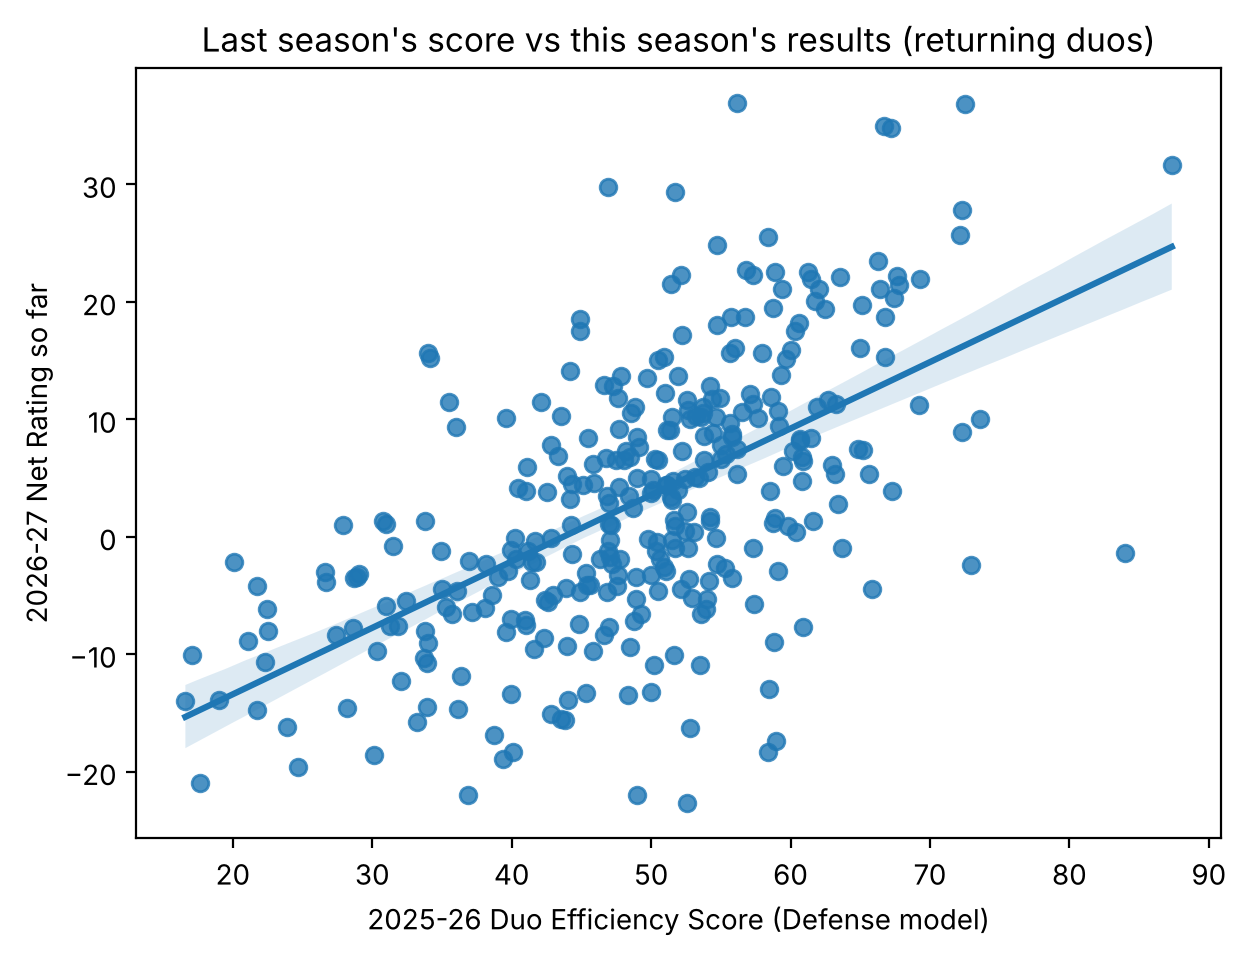

In [31]:
best_model = results.iloc[0]['Model']

fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(data=returning, x='DES_' + best_model, y='NetRtg_2026', ax=ax)
ax.set_xlabel(f'2025-26 Duo Efficiency Score ({best_model} model)')
ax.set_ylabel('2026-27 Net Rating so far')
ax.set_title('Last season\'s score vs this season\'s results (returning duos)')
plt.show()

In [32]:
# Last season's 30 best duos: are they still together and still winning?
check = best_duos[['TEAM', 'Lineups', 'NetRtg']].merge(this_season, on=['Lineups', 'TEAM'], how='left')
print('Still together with 100+ minutes in 2026-27:', 30 - check['NetRtg_2026'].isna().sum(), 'of 30')
print('Still positive Net Rating:', (check['NetRtg_2026'] > 0).sum())
check

Still together with 100+ minutes in 2026-27: 10 of 30
Still positive Net Rating: 7


,TEAM,Lineups,NetRtg,MIN_2026,NetRtg_2026
0,SAS,V. Wembanyama - D. Harper,27.0,347.0,31.6
1,BOS,D. White - H. González,27.1,101.0,-1.4
2,DEN,A. Gordon - N. Jokić,18.1,370.0,5.3
3,OKC,I. Hartenstein - C. Holmgren,20.9,NaN,NaN
4,LAC,K. Leonard - D. Garland,19.5,NaN,NaN
5,ATL,C. McCollum - D. Daniels,21.4,287.0,8.9
6,CHA,G. Williams - S. James,19.0,NaN,NaN
7,DET,A. Thompson - D. Jenkins,17.4,263.0,10.0
8,CLE,D. Mitchell - D. Wade,15.5,NaN,NaN
9,NYK,O. Anunoby - M. Robinson,16.7,NaN,NaN


## 9. Save the scored data for the application

In [33]:
keep = ['Lineups', 'Player_1', 'Player_2', 'TEAM', 'GP', 'MIN', 'OffRtg', 'DefRtg', 'NetRtg', 'TS%', 'AST/TO', 'REB%', 'PIE',
        'DES_Balanced', 'DES_Offense', 'DES_Defense', 'DES_Impact', 'Team_Rank']
duos[keep].to_csv('duos_scored_2025_26.csv', index=False)
duos_new.to_csv('duos_clean_2026_27.csv', index=False)
print('Saved', duos.shape[0], 'scored duos')

Saved 1259 scored duos


## Summary of findings
See the printed outputs above for exact values. The main findings:
1. **Shooting, rebounding and ball security** explain most of a duo's Net Rating; pace does not.
2. The **best duo per team depends on the model** for most teams: what you value changes the answer.
3. A small group of duos ranks near the top under **every** model. Those are the most efficient duos in the league.
4. Several teams have a **hub player** who appears in all three of their top duos.
5. Last season's score predicts this season only moderately, and the **Defense model** holds up best: defensive efficiency is more stable year to year than shooting.
